Publication adaptation: workspace labels and runtime paths have been renamed. Saved scientific results and embedded image bytes are retained from the recorded run; this source notebook has not been recomputed after that adaptation. Printed historical checksums describe that recorded run. Current released-file checksums are in the publication source map.

# Singh Day-7 HSPC program annotation from retained gene content

Gene-grounded descriptive annotation of the existing RNA-only eight-program NMF; no model refit, new differential-expression analysis, hypothesis test, enrichment rerun, or program selection. All eight retained programs are inspected. Program names are descriptive interpretations, not cell identities or causal mechanisms.

Environment: **chronoclone**, `/path/to/ChronoClone/.runtime/chronoclone`; kernel **chronoclone**.

Execution command:
`/path/to/ChronoClone/.runtime/chronoclone/bin/python /path/to/ChronoClone/analysis_workspace/singh/singh_weinreb_style_umaps_20260911/execute_notebook.py /path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911/0001_gene_grounded_program_annotations.ipynb`


In [1]:
from pathlib import Path
import hashlib, json, sys, platform, importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
BASE = Path('/path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911')
SOURCE = Path('/path/to/ChronoClone/analysis_workspace/singh/singh_reference_response_20260911/programs')
for sub in ['tables', 'reports', 'panels']:
    (BASE / sub).mkdir(exist_ok=True)
environment = {'name': 'chronoclone', 'path': '/path/to/ChronoClone/.runtime/chronoclone', 'kernel': 'chronoclone', 'executable': sys.executable, 'python': platform.python_version(), 'versions': {p: importlib.metadata.version(p) for p in ['numpy','pandas','matplotlib','nbformat','nbclient']}}
assert Path(sys.executable).parent.parent == Path(environment['path'])
(BASE / 'reports/environment.json').write_text(json.dumps(environment, indent=2))
display(environment)
inputs = [SOURCE / 'tables' / f for f in ['program_spectra.csv','program_query_genes.csv','program_identity_annotations.csv','program_enrichment_complete_family.csv','metaclone_mean_usage.csv','metaclone_program_conditional_intervals.csv','retrospective_mc3_mc7_characterization.csv','metaclone_depth.csv','metaclone_relative_usage_zscore.csv','06c_profile_plot_values.csv']]
inputs.append(SOURCE / '0002_rna_normalized_day7_programs.ipynb')
source_manifest = pd.DataFrame([{'source': str(p), 'sha256': hashlib.sha256(p.read_bytes()).hexdigest(), 'bytes': p.stat().st_size} for p in inputs])
source_manifest.to_csv(BASE / 'reports/source_manifest.csv', index=False)
display(source_manifest)
spectra = pd.read_csv(SOURCE / 'tables/program_spectra.csv', index_col=0)
query_genes = pd.read_csv(SOURCE / 'tables/program_query_genes.csv')
old_annotations = pd.read_csv(SOURCE / 'tables/program_identity_annotations.csv')
enrichment = pd.read_csv(SOURCE / 'tables/program_enrichment_complete_family.csv')
comparison = pd.read_csv(SOURCE / 'tables/retrospective_mc3_mc7_characterization.csv')
assert spectra.shape == (8, 2000)
assert list(spectra.index) == [f'P{i}' for i in range(1,9)]
assert not spectra.columns.duplicated().any()
assert len(enrichment) == 30624
Hn = spectra.div(spectra.sum(axis=1), axis=0)
specificity = Hn.pow(2).div(Hn.sum(axis=0), axis=1).fillna(0)
gene_rows = []
for program in spectra.index:
    loading_rank = spectra.loc[program].rank(method='first', ascending=False).astype(int)
    specificity_rank = specificity.loc[program].rank(method='first', ascending=False).astype(int)
    gene_rows.append(pd.DataFrame({'program': program, 'gene': spectra.columns, 'loading': spectra.loc[program].values, 'normalized_loading': Hn.loc[program].values, 'loading_rank': loading_rank.values, 'specificity': specificity.loc[program].values, 'specificity_rank': specificity_rank.values}))
gene_evidence = pd.concat(gene_rows, ignore_index=True)
gene_evidence.to_csv(BASE / 'tables/all_program_gene_evidence.csv', index=False)
# Verify the retained top-100 lists are reproduced; there is no new enrichment test.
for program in spectra.index:
    for query, rank_column in [('top_loading','loading_rank'), ('specificity','specificity_rank')]:
        available_queries = set(query_genes['query'])
        actual_query = query if query in available_queries else 'specific'
        saved = query_genes.loc[(query_genes.program == program) & (query_genes['query'] == actual_query)].sort_values('rank')['gene'].tolist()
        current = gene_evidence.loc[gene_evidence.program == program].sort_values(rank_column).head(100)['gene'].tolist()
        assert current == saved, (program, actual_query)
display({'spectra_shape': spectra.shape, 'gene_evidence_rows': len(gene_evidence), 'saved_query_types': query_genes['query'].unique().tolist(), 'complete_existing_enrichment_tests': len(enrichment)})
display(comparison)


{'name': 'chronoclone',
 'path': '/path/to/ChronoClone/.runtime/chronoclone',
 'kernel': 'chronoclone',
 'executable': '/path/to/ChronoClone/.runtime/chronoclone/bin/python',
 'python': '3.11.15',
 'versions': {'numpy': '2.4.6',
  'pandas': '2.3.3',
  'matplotlib': '3.11.0',
  'nbformat': '5.10.4',
  'nbclient': '0.11.0'}}

,source,sha256,bytes
0,/path/to/ChronoClone/research...,6bc1bd9a5510f29da81aa0f4614c2a9fd7e6728042bcfa...,227498
1,/path/to/ChronoClone/research...,9fa1846abbb09aed5c47e3d947b3b22b9fe097c82b76d7...,36545
2,/path/to/ChronoClone/research...,fad9012de4a431b894c0f7ff210cf793f20b8686db8fd6...,2242
3,/path/to/ChronoClone/research...,59b2b5f6a1400da47ec819ac5d17e51c43b16f56859f32...,4174404
4,/path/to/ChronoClone/research...,5a872a40b4173fe64e64f2fb9f920be72091ce27a07a35...,2757
5,/path/to/ChronoClone/research...,a211d530f7911861d9fb071ccbb9d1daf6174f8d1c6819...,14919
6,/path/to/ChronoClone/research...,bd81ad11df2bf106fb8074517b4aa01bf0c9481f9a23e7...,2063
7,/path/to/ChronoClone/research...,258573eb3e082b5b7d9d24ef80c814ebc36b94971bcd00...,177
8,/path/to/ChronoClone/research...,12d9e7b3eeef1494d86f5ba0393dcc77039c0e72da2db5...,2732
9,/path/to/ChronoClone/research...,11ae9a3bcf76acf7d4259334bf2dfdd4a858e32abc53c1...,1131


{'spectra_shape': (8, 2000),
 'gene_evidence_rows': 16000,
 'saved_query_types': ['top_loading', 'specific'],
 'complete_existing_enrichment_tests': 30624}

,program,MC3,MC7,MC3_minus_MC7,MC3_z,MC7_z,specific_genes,term,q_BH_all_queries_programs_terms
0,P1,0.216444,0.123713,0.092731,2.130489,-0.054750,"Adgrl4, Hlf, Gimap6, Mir99ahg, Itsn1, 2610307P...",Regulation Of Transcription By RNA Polymerase ...,2.571628e-03
1,P2,0.223571,0.177008,0.046563,0.522155,-0.752958,"Akr1c13, Fdps, S100a4, Nop10, Fabp5, Dbi, Nme1...",RNA Binding (GO:0003723),2.264065e-10
2,P3,0.092662,0.087439,0.005223,-0.271874,-0.556772,"Ube2c, Nusap1, Cenpf, Hmmr, Cenpa, Prc1, Ccnb1...",G2-M Checkpoint,1.007500e-32
3,P4,0.109489,0.160147,-0.050658,-1.678106,0.416981,"Trib3, Nupr1, Snhg12, Hsd17b1, 5430416N02Rik, ...",Cellular Responses To Stimuli R-HSA-8953897,3.759773e-13
4,P5,0.035533,0.176559,-0.141027,-2.343587,0.835654,"Tespa1, 4930519L02Rik, 2610307P16Rik, Nkg7, Sl...",Platelet Degranulation R-HSA-114608,2.071123e-03
5,P6,0.081233,0.078076,0.003157,0.286035,-0.018797,"Atad2, Pola1, Hells, Rad51b, Lig1, Rad51ap1, P...",E2F Targets,3.637599e-18
6,P7,0.107127,0.147005,-0.039878,-0.366951,1.515811,"Creb5, Myl10, Ankrd37, Tgm2, Bhlhe40, Jdp2, Fy...",Hypoxia,5.408813e-08
7,P8,0.133941,0.050053,0.083888,1.367577,-1.190183,"Ncam2, Med12l, Tgfbr3, C530008M17Rik, Zeb2, Pd...",Neuron Development (GO:0048666),1.161757e-03


In [2]:
# P1: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P1'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P1

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P1,Adgrl4,2.766063,0.006124,1,0.003483,1
1,P1,Hlf,2.562779,0.005674,3,0.003202,2
2,P1,Gimap6,2.555946,0.005659,4,0.002422,3
3,P1,Mir99ahg,2.333830,0.005167,6,0.002261,4
4,P1,Itsn1,2.176476,0.004819,8,0.002042,5
5,P1,2610307P16Rik,2.517490,0.005574,5,0.001851,6
6,P1,Parp8,1.741615,0.003856,35,0.001715,7
7,P1,Il15,1.448177,0.003206,51,0.001625,8
8,P1,Nrxn1,2.645211,0.005857,2,0.001423,9
9,P1,Ypel3,1.918714,0.004248,21,0.001419,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P1,Adgrl4,2.766063,0.006124,1,0.003483,1
1,P1,Nrxn1,2.645211,0.005857,2,0.001423,9
2,P1,Hlf,2.562779,0.005674,3,0.003202,2
3,P1,Gimap6,2.555946,0.005659,4,0.002422,3
4,P1,2610307P16Rik,2.517490,0.005574,5,0.001851,6
5,P1,Mir99ahg,2.333830,0.005167,6,0.002261,4
6,P1,Mecom,2.278423,0.005045,7,0.000948,28
7,P1,Itsn1,2.176476,0.004819,8,0.002042,5
8,P1,Rps3a1,2.126176,0.004708,9,0.000585,87
9,P1,Fau,2.115166,0.004683,10,0.000588,82


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
0,P1,"Adgrl4, Hlf, Gimap6, Mir99ahg, Itsn1, 2610307P...","Adgrl4, Nrxn1, Hlf, Gimap6, 2610307P16Rik, Mir...",Regulation Of Transcription By RNA Polymerase ...,GO_Biological_Process_2023,22,179,0.002572


Specificity top 40: Adgrl4, Hlf, Gimap6, Mir99ahg, Itsn1, 2610307P16Rik, Parp8, Il15, Nrxn1, Ypel3, Procr, Rora, Cnrip1, Ltb, Rnf220, Ly6a, Runx2, Fmnl2, Arid5b, Sox4, Alcam, Klf12, Evi5, Camk2d, Rbm47, Tcf7l2, Klhl24, Mecom, Thsd1, Ccser1, Calcrl, Nkx2-3, Zbtb20, Ikzf2, Crebrf, Zfp608, Ramp1, Car2, Tox, Prdm16
Loading top 25: Adgrl4, Nrxn1, Hlf, Gimap6, 2610307P16Rik, Mir99ahg, Mecom, Itsn1, Rps3a1, Fau, Malat1, Rps15a, Rpl11, Zbtb20, Rnf220, Rpl39, Sox4, Rps26, Ifitm1, Gas5, Ypel3, 2410006H16Rik, Lrmda, Runx2, Actb


In [3]:
# P2: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P2'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P2

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P2,Akr1c13,2.378548,0.009009,7,0.004093,1
1,P2,Fdps,1.957251,0.007413,27,0.003806,2
2,P2,S100a4,2.263057,0.008572,17,0.003776,3
3,P2,Nop10,2.489084,0.009428,2,0.003753,4
4,P2,Fabp5,2.143827,0.008120,21,0.003668,5
5,P2,Dbi,2.160102,0.008182,20,0.003594,6
6,P2,Nme1,2.359981,0.008939,9,0.003427,7
7,P2,Cycs,1.912146,0.007242,30,0.003407,8
8,P2,Atp5g1,2.336455,0.008850,11,0.003359,9
9,P2,Srm,2.048988,0.007761,24,0.003260,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P2,Ppia,2.560256,0.009697,1,0.002623,18
1,P2,Nop10,2.489084,0.009428,2,0.003753,4
2,P2,Actb,2.460018,0.009318,3,0.002404,21
3,P2,Ifitm1,2.415541,0.009149,4,0.002649,17
4,P2,Rpl11,2.401073,0.009094,5,0.002271,26
5,P2,Rps15a,2.385552,0.009036,6,0.002200,27
6,P2,Akr1c13,2.378548,0.009009,7,0.004093,1
7,P2,Rps3a1,2.373539,0.008990,8,0.002133,33
8,P2,Nme1,2.359981,0.008939,9,0.003427,7
9,P2,Tmsb4x,2.358919,0.008935,10,0.002387,22


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
1,P2,"Akr1c13, Fdps, S100a4, Nop10, Fabp5, Dbi, Nme1...","Ppia, Nop10, Actb, Ifitm1, Rpl11, Rps15a, Akr1...",RNA Binding (GO:0003723),GO_Molecular_Function_2023,21,64,2.264065e-10


Specificity top 40: Akr1c13, Fdps, S100a4, Nop10, Fabp5, Dbi, Nme1, Cycs, Atp5g1, Srm, Slc25a5, Ndufa4, S100a11, Ranbp1, Idi1, Txn1, Ifitm1, Ppia, Gem, Id1, Actb, Tmsb4x, S100a6, Alyref, Gm47283, Rpl11, Rps15a, Snhg4, Uqcrh, Marcksl1, Cd48, Msmo1, Rps3a1, H2afz, Hmgcs1, Rps26, Dut, Fau, Serpina3g, Rpl39
Loading top 25: Ppia, Nop10, Actb, Ifitm1, Rpl11, Rps15a, Akr1c13, Rps3a1, Nme1, Tmsb4x, Atp5g1, Ndufa4, Fau, Ranbp1, Slc25a5, Rps26, S100a4, H2afz, Rpl39, Dbi, Fabp5, Malat1, Txn1, Srm, Ubb


In [4]:
# P3: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P3'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P3

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P3,Ube2c,3.749120,0.013506,1,0.012022,1
1,P3,Nusap1,3.032169,0.010923,4,0.010260,2
2,P3,Cenpf,2.942173,0.010599,6,0.010072,3
3,P3,Hmmr,2.732206,0.009842,11,0.009842,4
4,P3,Cenpa,3.162229,0.011391,2,0.008759,5
5,P3,Prc1,2.761729,0.009949,10,0.008110,6
6,P3,Ccnb1,2.278822,0.008209,20,0.007711,7
7,P3,Tpx2,2.817495,0.010150,9,0.007438,8
8,P3,Birc5,2.989666,0.010770,5,0.007314,9
9,P3,Cenpe,2.273811,0.008191,22,0.007191,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P3,Ube2c,3.749120,0.013506,1,0.012022,1
1,P3,Cenpa,3.162229,0.011391,2,0.008759,5
2,P3,Top2a,3.073033,0.011070,3,0.005524,22
3,P3,Nusap1,3.032169,0.010923,4,0.010260,2
4,P3,Birc5,2.989666,0.010770,5,0.007314,9
5,P3,Cenpf,2.942173,0.010599,6,0.010072,3
6,P3,Cdca8,2.917543,0.010510,7,0.007097,12
7,P3,H2afx,2.913778,0.010496,8,0.005308,23
8,P3,Tpx2,2.817495,0.010150,9,0.007438,8
9,P3,Prc1,2.761729,0.009949,10,0.008110,6


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
2,P3,"Ube2c, Nusap1, Cenpf, Hmmr, Cenpa, Prc1, Ccnb1...","Ube2c, Cenpa, Top2a, Nusap1, Birc5, Cenpf, Cdc...",G2-M Checkpoint,MSigDB_Hallmark_2020,32,40,1.007500e-32


Specificity top 40: Ube2c, Nusap1, Cenpf, Hmmr, Cenpa, Prc1, Ccnb1, Tpx2, Birc5, Cenpe, Cdc20, Cdca8, Ccnb2, Aurka, Plk1, Mki67, Kif11, Cdca3, Ccna2, Lockd, Kif23, Top2a, H2afx, Knl1, Incenp, Pttg1, Cdk1, Cks2, Tuba1c, Tubb4b, Kif20b, Ect2, Ckap5, Cenpp, Smc2, Kif15, Hist1h1b, Neil3, Pbk, Smc4
Loading top 25: Ube2c, Cenpa, Top2a, Nusap1, Birc5, Cenpf, Cdca8, H2afx, Tpx2, Prc1, Hmmr, Tubb4b, Mki67, Cks2, Ccnb2, Lockd, Kif11, Incenp, Cdk1, Ccnb1, Cdca3, Cenpe, Ccna2, Cdc20, Knl1


In [5]:
# P4: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P4'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P4

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P4,Trib3,2.375645,0.007580,9,0.006846,1
1,P4,Nupr1,2.890427,0.009222,3,0.006546,2
2,P4,Snhg12,3.119710,0.009954,1,0.006516,3
3,P4,Hsd17b1,1.924179,0.006139,21,0.005190,4
4,P4,5430416N02Rik,1.947212,0.006213,20,0.004816,5
5,P4,Atf5,1.910756,0.006096,22,0.004808,6
6,P4,Snhg1,3.009255,0.009601,2,0.004294,7
7,P4,Cebpb,2.508628,0.008004,5,0.004115,8
8,P4,Mthfd2,2.449869,0.007816,8,0.004101,9
9,P4,Asns,2.083899,0.006649,17,0.003692,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P4,Snhg12,3.119710,0.009954,1,0.006516,3
1,P4,Snhg1,3.009255,0.009601,2,0.004294,7
2,P4,Nupr1,2.890427,0.009222,3,0.006546,2
3,P4,2410006H16Rik,2.688979,0.008579,4,0.002709,18
4,P4,Cebpb,2.508628,0.008004,5,0.004115,8
5,P4,Gas5,2.491809,0.007950,6,0.002066,25
6,P4,Zfas1,2.475275,0.007898,7,0.003483,11
7,P4,Mthfd2,2.449869,0.007816,8,0.004101,9
8,P4,Trib3,2.375645,0.007580,9,0.006846,1
9,P4,Eif4ebp1,2.310033,0.007370,10,0.002477,22


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
3,P4,"Trib3, Nupr1, Snhg12, Hsd17b1, 5430416N02Rik, ...","Snhg12, Snhg1, Nupr1, 2410006H16Rik, Cebpb, Ga...",Cellular Responses To Stimuli R-HSA-8953897,Reactome_2022,24,66,3.759773e-13


Specificity top 40: Trib3, Nupr1, Snhg12, Hsd17b1, 5430416N02Rik, Atf5, Snhg1, Cebpb, Mthfd2, Asns, Zfas1, Atf4, Psph, Fam129a, Herpud1, Ddit3, Soat2, 2410006H16Rik, 1110038B12Rik, Snhg5, Slc7a11, Eif4ebp1, Chac1, Snhg16, Gas5, Txnip, Angptl6, Serp1, Cebpg, Srm, P2rx3, Snhg15, Bbc3, Ier2, Jund, Grb10, Cd69, Xbp1, Cytip, Ppp1r15a
Loading top 25: Snhg12, Snhg1, Nupr1, 2410006H16Rik, Cebpb, Gas5, Zfas1, Mthfd2, Trib3, Eif4ebp1, Rps3a1, Malat1, 1110038B12Rik, Atf4, Rps15a, Fau, Asns, Rpl39, Rps26, 5430416N02Rik, Hsd17b1, Atf5, Ppia, Actb, Rpl11


In [6]:
# P5: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P5'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P5

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P5,Tespa1,1.997240,0.005320,10,0.003318,1
1,P5,4930519L02Rik,2.182754,0.005814,5,0.002754,2
2,P5,2610307P16Rik,2.506340,0.006676,2,0.002656,3
3,P5,Nkg7,2.045175,0.005448,8,0.002508,4
4,P5,Slc22a3,1.964638,0.005233,13,0.002359,5
5,P5,Cd48,1.976512,0.005265,11,0.002354,6
6,P5,Cdk6,2.555725,0.006808,1,0.002042,7
7,P5,Pcdh7,2.199786,0.005859,4,0.002032,8
8,P5,Lat2,1.051950,0.002802,103,0.001796,9
9,P5,Adgrg3,1.057658,0.002817,100,0.001720,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P5,Cdk6,2.555725,0.006808,1,0.002042,7
1,P5,2610307P16Rik,2.506340,0.006676,2,0.002656,3
2,P5,Maml3,2.255183,0.006007,3,0.001666,13
3,P5,Pcdh7,2.199786,0.005859,4,0.002032,8
4,P5,4930519L02Rik,2.182754,0.005814,5,0.002754,2
5,P5,Nrxn1,2.127911,0.005668,6,0.001333,20
6,P5,Arhgap15,2.083437,0.005550,7,0.001333,19
7,P5,Nkg7,2.045175,0.005448,8,0.002508,4
8,P5,Malat1,2.019435,0.005379,9,0.000751,70
9,P5,Tespa1,1.997240,0.005320,10,0.003318,1


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
4,P5,"Tespa1, 4930519L02Rik, 2610307P16Rik, Nkg7, Sl...","Cdk6, 2610307P16Rik, Maml3, Pcdh7, 4930519L02R...",Platelet Degranulation R-HSA-114608,Reactome_2022,7,20,0.002071


Specificity top 40: Tespa1, 4930519L02Rik, 2610307P16Rik, Nkg7, Slc22a3, Cd48, Cdk6, Pcdh7, Lat2, Adgrg3, Serpinb1a, Dnajc6, Maml3, Plac8, Ramp1, Scin, Cd34, Clec4e, Arhgap15, Nrxn1, Dach1, Sox4, Gm15657, Fcer1g, Bin1, Fam117a, Cpa3, Mir142hg, Ndrg1, Bcl2, Kctd1, Ikzf2, Gm4258, Slco3a1, Pecam1, Gzmb, Cd37, A630072M18Rik, Usp40, Itga2b
Loading top 25: Cdk6, 2610307P16Rik, Maml3, Pcdh7, 4930519L02Rik, Nrxn1, Arhgap15, Nkg7, Malat1, Tespa1, Cd48, Dach1, Slc22a3, Cux1, Fau, Tmsb4x, Rps3a1, Rpl11, Angpt1, Rps26, Actb, Rpl39, Rps15a, Ppia, Mir142hg


In [7]:
# P6: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P6'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P6

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P6,Atad2,3.682316,0.010784,3,0.007192,1
1,P6,Pola1,3.758008,0.011006,2,0.007048,2
2,P6,Hells,3.324940,0.009737,5,0.006870,3
3,P6,Rad51b,4.031928,0.011808,1,0.006726,4
4,P6,Lig1,3.144602,0.009209,7,0.006506,5
5,P6,Rad51ap1,2.613022,0.007652,19,0.005679,6
6,P6,Pclaf,3.170961,0.009286,6,0.005458,7
7,P6,Tk1,2.830637,0.008290,13,0.005393,8
8,P6,Rrm2,2.633042,0.007711,18,0.005369,9
9,P6,Gmnn,3.122265,0.009144,8,0.005308,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P6,Rad51b,4.031928,0.011808,1,0.006726,4
1,P6,Pola1,3.758008,0.011006,2,0.007048,2
2,P6,Atad2,3.682316,0.010784,3,0.007192,1
3,P6,Top2a,3.560915,0.010428,4,0.004902,14
4,P6,Hells,3.324940,0.009737,5,0.006870,3
5,P6,Pclaf,3.170961,0.009286,6,0.005458,7
6,P6,Lig1,3.144602,0.009209,7,0.006506,5
7,P6,Gmnn,3.122265,0.009144,8,0.005308,10
8,P6,Tipin,3.081577,0.009025,9,0.004331,16
9,P6,Hist1h1b,3.025041,0.008859,10,0.004936,12


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
5,P6,"Atad2, Pola1, Hells, Rad51b, Lig1, Rad51ap1, P...","Rad51b, Pola1, Atad2, Top2a, Hells, Pclaf, Lig...",E2F Targets,MSigDB_Hallmark_2020,23,39,3.637599e-18


Specificity top 40: Atad2, Pola1, Hells, Rad51b, Lig1, Rad51ap1, Pclaf, Tk1, Rrm2, Gmnn, Mcm4, Hist1h1b, Pcna, Top2a, Tyms, Tipin, Cep128, Diaph3, Mcm6, Cenpp, Spc24, Smc2, Slbp, Kif15, Pbk, Fbxo5, Neil3, Smc4, Dut, Brip1os, Pard3b, Gm47283, Mki67, Plcb1, Slc8a1, Knl1, Tuba1b, Cdk1, Incenp, Macrod2
Loading top 25: Rad51b, Pola1, Atad2, Top2a, Hells, Pclaf, Lig1, Gmnn, Tipin, Hist1h1b, Pcna, Mcm4, Tk1, Diaph3, Smc2, Mcm6, Tyms, Rrm2, Rad51ap1, Cep128, Cenpp, Slbp, Spc24, Dut, Smc4


In [8]:
# P7: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P7'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P7

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P7,Creb5,2.243785,0.007507,2,0.003678,1
1,P7,Myl10,2.398340,0.008024,1,0.002923,2
2,P7,Ankrd37,1.284966,0.004299,32,0.002731,3
3,P7,Tgm2,1.576966,0.005276,11,0.002670,4
4,P7,Bhlhe40,1.030222,0.003447,57,0.002493,5
5,P7,Jdp2,1.492100,0.004992,18,0.002430,6
6,P7,Fyb2,0.690927,0.002311,113,0.002311,7
7,P7,Aldoc,1.059123,0.003543,52,0.002091,8
8,P7,Bnip3,1.578869,0.005282,10,0.002043,9
9,P7,Eno1,1.856618,0.006211,4,0.002028,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P7,Myl10,2.398340,0.008024,1,0.002923,2
1,P7,Creb5,2.243785,0.007507,2,0.003678,1
2,P7,Pgk1,1.859166,0.006220,3,0.001361,30
3,P7,Eno1,1.856618,0.006211,4,0.002028,10
4,P7,Tpi1,1.761906,0.005894,5,0.001381,28
5,P7,Aldoa,1.749171,0.005852,6,0.001215,35
6,P7,Trpc6,1.736883,0.005811,7,0.001744,15
7,P7,Gt(ROSA)26Sor,1.619563,0.005418,8,0.001818,11
8,P7,Prtn3,1.581446,0.005291,9,0.001510,23
9,P7,Bnip3,1.578869,0.005282,10,0.002043,9


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
6,P7,"Creb5, Myl10, Ankrd37, Tgm2, Bhlhe40, Jdp2, Fy...","Myl10, Creb5, Pgk1, Eno1, Tpi1, Aldoa, Trpc6, ...",Hypoxia,MSigDB_Hallmark_2020,17,53,5.408813e-08


Specificity top 40: Creb5, Myl10, Ankrd37, Tgm2, Bhlhe40, Jdp2, Fyb2, Aldoc, Bnip3, Eno1, Gt(ROSA)26Sor, Ier3, Timp3, Fads2, Trpc6, Egln3, Socs3, Csf3r, Junb, Fos, Padi4, Ltb, Prtn3, Nol4l, Plac8, Fmnl2, P4ha1, Tpi1, Ern1, Pgk1, Egr1, Adrb2, Arhgap6, Gm15283, Aldoa, Fbxo7, Jun, Plek, Igfbp7, Pf4
Loading top 25: Myl10, Creb5, Pgk1, Eno1, Tpi1, Aldoa, Trpc6, Gt(ROSA)26Sor, Prtn3, Bnip3, Tgm2, Ier3, Malat1, Pim1, Ern1, Fau, Arhgap6, Jdp2, Rps3a1, Rps15a, Rpl11, Rpl39, Fads2, Rps26, Cux1


In [9]:
# P8: inspect both absolute spectrum weights and specificity, not only the selected ontology label.
program = 'P8'
rows = gene_evidence.loc[gene_evidence.program == program]
display(Markdown('## ' + program))
display(rows.sort_values('specificity_rank').head(40).reset_index(drop=True))
display(Markdown('Highest raw-loading genes'))
display(rows.sort_values('loading_rank').head(25).reset_index(drop=True))
display(old_annotations.loc[old_annotations.program == program])
print('Specificity top 40:', ', '.join(rows.sort_values('specificity_rank').head(40).gene))
print('Loading top 25:', ', '.join(rows.sort_values('loading_rank').head(25).gene))


## P8

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P8,Ncam2,3.164437,0.006466,3,0.003233,1
1,P8,Med12l,3.224013,0.006587,1,0.002846,2
2,P8,Tgfbr3,3.174958,0.006487,2,0.002743,3
3,P8,C530008M17Rik,2.943636,0.006015,4,0.002396,4
4,P8,Zeb2,2.782603,0.005686,5,0.001915,5
5,P8,Pdzk1ip1,1.590434,0.003250,55,0.001869,6
6,P8,Pim2,2.276648,0.004652,13,0.001796,7
7,P8,Lhcgr,1.501469,0.003068,66,0.001764,8
8,P8,Enah,2.416951,0.004938,9,0.001758,9
9,P8,Stxbp6,2.357990,0.004818,11,0.001744,10


Highest raw-loading genes

,program,gene,loading,normalized_loading,loading_rank,specificity,specificity_rank
0,P8,Med12l,3.224013,0.006587,1,0.002846,2
1,P8,Tgfbr3,3.174958,0.006487,2,0.002743,3
2,P8,Ncam2,3.164437,0.006466,3,0.003233,1
3,P8,C530008M17Rik,2.943636,0.006015,4,0.002396,4
4,P8,Zeb2,2.782603,0.005686,5,0.001915,5
5,P8,Prkg1,2.767585,0.005655,6,0.001631,12
6,P8,Dach1,2.466995,0.005041,7,0.001229,28
7,P8,Hdac9,2.451339,0.005009,8,0.001424,19
8,P8,Enah,2.416951,0.004938,9,0.001758,9
9,P8,Runx1,2.402112,0.004908,10,0.000869,53


,program,specific_genes,loading_genes,term,library,overlap,n_term_in_background,q_BH_all_queries_programs_terms
7,P8,"Ncam2, Med12l, Tgfbr3, C530008M17Rik, Zeb2, Pd...","Med12l, Tgfbr3, Ncam2, C530008M17Rik, Zeb2, Pr...",Neuron Development (GO:0048666),GO_Biological_Process_2023,7,18,0.001162


Specificity top 40: Ncam2, Med12l, Tgfbr3, C530008M17Rik, Zeb2, Pdzk1ip1, Pim2, Lhcgr, Enah, Stxbp6, Plxnc1, Prkg1, Adamts6, Plcl1, Cd38, Itga6, Prickle1, Hk2, Hdac9, Slc8a1, Tbxas1, B3galt1, Palld, Slamf1, Pbx1, Prkca, Gda, Dach1, Rhoj, Lpp, Nedd4l, Cpne8, Slfn2, Ecm1, Il4, Clu, Csgalnact1, Hacd4, Slc18a2, Apoe
Loading top 25: Med12l, Tgfbr3, Ncam2, C530008M17Rik, Zeb2, Prkg1, Dach1, Hdac9, Enah, Runx1, Stxbp6, Pbx1, Pim2, Csgalnact1, Mecom, Tbxas1, Mctp1, Prkca, Inpp4b, Akr1c13, Angpt1, Adamts6, Nedd4l, St3gal1, Itga6


## Literature-informed curation

The records below are human-readable interpretations of the retained gene weights, not newly fitted classes or statistically selected metaclone signatures. Literature supports roles of individual genes in the stated experimental contexts; it does not establish that these NMF programs cause the observed clonal histories. In particular, HSPC is the pooled input annotation throughout. No HSC/MPP subdivision is reconstructed. Three representative genes per program are curated for the loading display from the first 40 loading or specificity ranks; they are not automatically the three highest genes.


In [10]:
# Descriptive curation registry: interpretation is explicit and separate from measured weights.
annotation_records = [
    {'program':'P1', 'label':'HSC-associated regulation', 'plot_label':'HSC-associated regulation', 'anchors':['Hlf','Mecom','Procr'], 'additional_genes':['Ly6a','Prdm16','Rora','Sox4'], 'interpretation':'Hlf, Mecom, Procr and Ly6a support an HSC-associated regulatory/marker mixture within the pooled HSPC compartment.', 'boundary':'Not a purified HSC identity, measured quiescence, self-renewal assay, or a new HSC/MPP subdivision. Adgrl4 and Nrxn1 contribute strongly and the spectrum is mixed.', 'references':['Komorowska2017','Yokomizo2019']},
    {'program':'P2', 'label':'Biosynthesis / metabolism', 'plot_label':'Biosynthesis / metabolism', 'anchors':['Nop10','Fdps','Ndufa4'], 'additional_genes':['Fabp5','Dbi','Nme1','Cycs','Srm','Rpl11','Rps15a'], 'interpretation':'Ribosomal/RNA-processing genes occur together with lipid/isoprenoid and respiratory-metabolic machinery; this is a broad biosynthetic/metabolic component.', 'boundary':'Not a lineage-specific program or evidence of greater translation, respiration, or metabolic flux. Ndufa4 is assigned to respiratory complex IV, not complex I.', 'references':['Khanna2006','Balsa2012']},
    {'program':'P3', 'label':'G2/M mitosis', 'plot_label':'G2/M mitosis', 'anchors':['Ube2c','Ccnb1','Cenpf'], 'additional_genes':['Nusap1','Cenpa','Tpx2','Birc5','Cdc20','Plk1','Aurka'], 'interpretation':'A coherent mitotic/spindle/chromosome-segregation component, consistent with the existing G2-M Checkpoint annotation.', 'boundary':'Program usage is not a measured division rate and does not identify lineage output or self-renewal.', 'references':['Passegue2005']},
    {'program':'P4', 'label':'Integrated stress response', 'plot_label':'Integrated stress response', 'anchors':['Atf4','Trib3','Asns'], 'additional_genes':['Atf5','Nupr1','Ddit3','Chac1','Slc7a11','Ppp1r15a','Herpud1'], 'interpretation':'ATF4-associated amino-acid, redox and proteostasis response genes provide a more specific description than the generic cellular-stimuli term.', 'boundary':'A transcriptional stress-associated mixture, not a direct assay of eIF2alpha phosphorylation, ATF4 protein activity, stress cause, injury, or inferior stem-cell function; ISR can support HSC persistence.', 'references':['vanGalen2018']},
    {'program':'P5', 'label':'CDK6 / immune-associated', 'plot_label':'CDK6 / immune-associated', 'anchors':['Cdk6','Cd48','Nkg7'], 'additional_genes':['Tespa1','Lat2','Fcer1g','Clec4e','Cpa3','Gzmb','Itga2b'], 'interpretation':'Cdk6 and Cd48 place the component in a progenitor-activation context, accompanied by immune-signaling/granule genes spanning more than one mature lineage.', 'boundary':'Mixed program: not platelet identity, NK-cell identity, proven quiescence exit, or a specific commitment route. Cdk6 RNA does not establish CDK6 protein or kinase activity.', 'references':['Laurenti2015','Boles2011','Ng2020','Wang2014']},
    {'program':'P6', 'label':'DNA replication / repair', 'plot_label':'DNA replication / repair', 'anchors':['Pola1','Mcm4','Rad51b'], 'additional_genes':['Pcna','Tk1','Rrm2','Lig1','Rad51ap1','Hells','Gmnn','Tyms'], 'interpretation':'Replication licensing/synthesis and homologous-recombination-associated genes distinguish this component from the predominantly mitotic P3 program; consistent with existing E2F Targets annotation.', 'boundary':'Not evidence of DNA damage, mutation burden, measured repair activity, or greater cell-division rate.', 'references':['Passegue2005']},
    {'program':'P7', 'label':'Glycolysis / hypoxia-associated', 'plot_label':'Glycolysis / hypoxia-associated', 'anchors':['Pgk1','Bnip3','Egln3'], 'additional_genes':['Eno1','Tpi1','Aldoa','Aldoc','Bhlhe40','Ankrd37','Csf3r','Prtn3'], 'interpretation':'A coherent glycolytic and hypoxia-response-associated core occurs with immediate-early and some myeloid-associated genes.', 'boundary':'Not measured oxygen tension, glycolytic flux, or a causal driver of faster differentiation. Glycolysis can also support HSC quiescence; the myeloid genes do not establish a pure granulocytic program.', 'references':['Takubo2013']},
    {'program':'P8', 'label':'HSPC regulation / adhesion', 'plot_label':'HSPC regulation / adhesion', 'anchors':['Pbx1','Zeb2','Tgfbr3'], 'additional_genes':['Med12l','Runx1','Mecom','Ncam2','Enah','Itga6','Slamf1','Palld'], 'interpretation':'Hematopoietic regulatory genes coexist with receptors, adhesion and cytoskeletal genes; this provides an HSPC-relevant description of a mixed component.', 'boundary':'Not neuronal fate, a pure HSC identity, proven TGF-beta pathway activity, measured adhesion, or self-renewal. MED12L is not MED12; Ncam2 alone does not establish a hematopoietic mechanism.', 'references':['Ficara2008','Goossens2011']},
]
references = [
 {'key':'Komorowska2017','citation':'Komorowska, K., Doyle, A., Wahlestedt, M., et al. (2017). Hepatic Leukemia Factor Maintains Quiescence of Hematopoietic Stem Cells and Protects the Stem Cell Pool during Regeneration. Cell Reports 21, 3514–3523.','doi':'10.1016/j.celrep.2017.11.084','url':'https://pubmed.ncbi.nlm.nih.gov/29262330/','support':'Mouse Hlf deletion impaired regenerative HSC maintenance and reduced quiescence. This supports Hlf-associated context, not quiescence measurements in Singh cells.'},
 {'key':'Yokomizo2019','citation':'Yokomizo, T., Watanabe, N., Umemoto, T., et al. (2019). Hlf marks the developmental pathway for hematopoietic stem cells but not for erythro-myeloid progenitors. Journal of Experimental Medicine 216, 1599–1614.','doi':'10.1084/jem.20181399','url':'https://pmc.ncbi.nlm.nih.gov/articles/PMC6605751/','support':'Developmental mouse Hlf-positive cells contained Hlf, Mecom and Procr-associated HSC expression; developmental setting, not an adult lineage identity classifier.'},
 {'key':'Khanna2006','citation':'Khanna, M., Wu, H., Johansson, C., Caizergues-Ferrer, M., and Feigon, J. (2006). Structural study of the H/ACA snoRNP components Nop10p and the 3-prime hairpin of U65 snoRNA. RNA 12, 40–52.','doi':'10.1261/rna.2221606','url':'https://pubmed.ncbi.nlm.nih.gov/16373493/','support':'Nop10-related snoRNP structure and RNA modification. Molecular-function support, not hematopoietic-state evidence.'},
 {'key':'Balsa2012','citation':'Balsa, E., Marco, R., Perales-Clemente, E., Szklarczyk, R., Calvo, E., Landazuri, M.O., and Enriquez, J.A. (2012). NDUFA4 is a subunit of complex IV of the mammalian electron transport chain. Cell Metabolism 16, 378–386.','doi':'10.1016/j.cmet.2012.07.015','url':'https://pubmed.ncbi.nlm.nih.gov/22902835/','support':'NDUFA4 respiratory-complex-IV function; does not measure metabolic flux here.'},
 {'key':'Passegue2005','citation':'Passegue, E., Wagers, A.J., Giuriato, S., Anderson, W.C., and Weissman, I.L. (2005). Global analysis of proliferation and cell cycle gene expression in the regulation of hematopoietic stem and progenitor cell fates. Journal of Experimental Medicine 202, 1599–1611.','doi':'10.1084/jem.20050967','url':'https://pubmed.ncbi.nlm.nih.gov/16330818/','support':'Primary HSPC cell-cycle and proliferation study; contextualizes phase-associated expression without equating NMF usage with division rate.'},
 {'key':'vanGalen2018','citation':'van Galen, P., Mbong, N., Kreso, A., Schoof, E.M., Wagenblast, E., Ng, S.W.K., Krivdova, G., Jin, L., Nakauchi, H., and Dick, J.E. (2018). Integrated Stress Response Activity Marks Stem Cells in Normal Hematopoiesis and Leukemia. Cell Reports 25, 1109–1117.e5.','doi':'10.1016/j.celrep.2018.10.021','url':'https://www.sciencedirect.com/science/article/pii/S2211124718315973','support':'Primary human HSC study links ATF4/ISR and amino-acid deprivation response with persistence. Prevents interpreting stress-associated expression as loss of stem function.'},
 {'key':'Laurenti2015','citation':'Laurenti, E., Frelin, C., Xie, S., et al. (2015). CDK6 levels regulate quiescence exit in human hematopoietic stem cells. Cell Stem Cell 16, 302–313.','doi':'10.1016/j.stem.2015.01.017','url':'https://pubmed.ncbi.nlm.nih.gov/25704240/','support':'CDK6 protein governs quiescence-exit kinetics in purified human HSC subsets. This motivates activation-associated interpretation, not proof from RNA or a new HSC subdivision.'},
 {'key':'Boles2011','citation':'Boles, N.C., Lin, K.K., Lukov, G.L., Bowman, T.V., Baldridge, M.T., and Goodell, M.A. (2011). CD48 on hematopoietic progenitors regulates stem cells and suppresses tumor formation. Blood 118, 80–87.','doi':'10.1182/blood-2010-12-322339','url':'https://pmc.ncbi.nlm.nih.gov/articles/PMC3139389/','support':'CD48 protein was present on short-term progenitors and excluded from quiescent LT-HSCs in the examined mouse setting. Not a direct classification from Cd48 RNA here.'},
 {'key':'Ng2020','citation':'Ng, S.S., De Labastida Rivera, F., Yan, J., et al. (2020). The NK cell granule protein NKG7 regulates cytotoxic granule exocytosis and inflammation. Nature Immunology 21, 1205–1218.','doi':'10.1038/s41590-020-0758-6','url':'https://pubmed.ncbi.nlm.nih.gov/32839608/','support':'NKG7 granule/immune-effector function; its presence alongside heterogeneous genes does not establish NK identity.'},
 {'key':'Wang2014','citation':'Wang, D., Zheng, M., Qiu, Y., et al. (2014). Tespa1 negatively regulates Fc-epsilon-RI-mediated signaling and the mast cell-mediated allergic response. Journal of Experimental Medicine.','doi':'10.1084/jem.20140470','url':'https://pubmed.ncbi.nlm.nih.gov/25422497/','support':'Tespa1 participates in mast-cell receptor signaling, demonstrating that this P5 anchor is not a platelet-specific marker.'},
 {'key':'Takubo2013','citation':'Takubo, K., Nagamatsu, G., Kobayashi, C.I., et al. (2013). Regulation of glycolysis by Pdk functions as a metabolic checkpoint for cell cycle quiescence in hematopoietic stem cells. Cell Stem Cell 12, 49–61.','doi':'10.1016/j.stem.2012.10.011','url':'https://pubmed.ncbi.nlm.nih.gov/23290136/','support':'Functional mouse HSC evidence that glycolysis can support quiescence; forbids treating a glycolytic RNA program as a universal differentiation-speed marker.'},
 {'key':'Ficara2008','citation':'Ficara, F., Murphy, M.J., Lin, M., and Cleary, M.L. (2008). Pbx1 regulates self-renewal of long-term hematopoietic stem cells by maintaining their quiescence. Cell Stem Cell 2, 484–496.','doi':'10.1016/j.stem.2008.03.004','url':'https://pmc.ncbi.nlm.nih.gov/articles/PMC2416441/','support':'Conditional mouse Pbx1 deletion altered HSC maintenance and TGF-beta responses; context for a loaded regulator, not proof of the corresponding function in MC3.'},
 {'key':'Goossens2011','citation':'Goossens, S., Janzen, V., Bartunkova, S., et al. (2011). The EMT regulator Zeb2/Sip1 is essential for murine embryonic hematopoietic stem/progenitor cell differentiation and mobilization. Blood.','doi':'10.1182/blood-2010-08-300236','url':'https://pubmed.ncbi.nlm.nih.gov/21355089/','support':'Zeb2 deletion alters embryonic HSPC differentiation, mobilization and adhesion. Supports hematopoietic relevance rather than the misleading neuronal label; does not imply the same embryonic mechanism here.'},
]
annotations = pd.DataFrame(annotation_records).set_index('program')
assert list(annotations.index) == list(spectra.index)
assert set(sum(annotations.references.tolist(), [])) <= {r['key'] for r in references}
curated_genes = pd.DataFrame([{'program': p, 'gene': g, 'display_order': j + 1} for p, row in annotations.iterrows() for j, g in enumerate(row.anchors)])
curated_genes = curated_genes.merge(gene_evidence, on=['program','gene'], validate='one_to_one')
assert len(curated_genes) == 24
assert ((curated_genes.loading_rank <= 40) | (curated_genes.specificity_rank <= 40)).all()
curated_genes.to_csv(BASE / 'tables/representative_gene_display.csv', index=False)
annotations.reset_index().to_json(BASE / 'tables/program_annotations.json', orient='records', indent=2)
annotations.map(lambda x: '; '.join(x) if isinstance(x, list) else x).to_csv(BASE / 'tables/program_annotations.csv')
pd.DataFrame(references).to_csv(BASE / 'tables/primary_literature.csv', index=False)
display(annotations[['label','anchors','interpretation','boundary']])
display(curated_genes[['program','gene','loading_rank','specificity_rank']])
display(pd.DataFrame(references))
# Preserve all pre-existing annotations and q-values as source evidence; no significance is attached to the new descriptive labels.
old_annotations.to_csv(BASE / 'tables/retained_original_enrichment_labels.csv', index=False)
annotated_comparison = comparison.merge(annotations[['label']].reset_index(), on='program', validate='one_to_one')
annotated_comparison.to_csv(BASE / 'tables/annotated_mc3_mc7_comparison.csv', index=False)
display(annotated_comparison[['program','label','MC3','MC7','MC3_minus_MC7']])
print('The retained program with the largest absolute MC3-minus-MC7 difference is:', annotated_comparison.loc[annotated_comparison.MC3_minus_MC7.abs().idxmax(), 'program'])


,label,anchors,interpretation,boundary
program,,,,
P1,HSC-associated regulation,"[Hlf, Mecom, Procr]","Hlf, Mecom, Procr and Ly6a support an HSC-asso...","Not a purified HSC identity, measured quiescen..."
P2,Biosynthesis / metabolism,"[Nop10, Fdps, Ndufa4]",Ribosomal/RNA-processing genes occur together ...,Not a lineage-specific program or evidence of ...
P3,G2/M mitosis,"[Ube2c, Ccnb1, Cenpf]",A coherent mitotic/spindle/chromosome-segregat...,Program usage is not a measured division rate ...
P4,Integrated stress response,"[Atf4, Trib3, Asns]","ATF4-associated amino-acid, redox and proteost...","A transcriptional stress-associated mixture, n..."
P5,CDK6 / immune-associated,"[Cdk6, Cd48, Nkg7]",Cdk6 and Cd48 place the component in a progeni...,"Mixed program: not platelet identity, NK-cell ..."
P6,DNA replication / repair,"[Pola1, Mcm4, Rad51b]",Replication licensing/synthesis and homologous...,"Not evidence of DNA damage, mutation burden, m..."
P7,Glycolysis / hypoxia-associated,"[Pgk1, Bnip3, Egln3]",A coherent glycolytic and hypoxia-response-ass...,"Not measured oxygen tension, glycolytic flux, ..."
P8,HSPC regulation / adhesion,"[Pbx1, Zeb2, Tgfbr3]",Hematopoietic regulatory genes coexist with re...,"Not neuronal fate, a pure HSC identity, proven..."


,program,gene,loading_rank,specificity_rank
0,P1,Hlf,3,2
1,P1,Mecom,7,28
2,P1,Procr,166,11
3,P2,Nop10,2,4
4,P2,Fdps,27,2
5,P2,Ndufa4,12,12
6,P3,Ube2c,1,1
7,P3,Ccnb1,20,7
8,P3,Cenpf,6,3
9,P4,Atf4,14,12


,key,citation,doi,url,support
0,Komorowska2017,"Komorowska, K., Doyle, A., Wahlestedt, M., et ...",10.1016/j.celrep.2017.11.084,https://pubmed.ncbi.nlm.nih.gov/29262330/,Mouse Hlf deletion impaired regenerative HSC m...
1,Yokomizo2019,"Yokomizo, T., Watanabe, N., Umemoto, T., et al...",10.1084/jem.20181399,https://pmc.ncbi.nlm.nih.gov/articles/PMC6605751/,Developmental mouse Hlf-positive cells contain...
2,Khanna2006,"Khanna, M., Wu, H., Johansson, C., Caizergues-...",10.1261/rna.2221606,https://pubmed.ncbi.nlm.nih.gov/16373493/,Nop10-related snoRNP structure and RNA modific...
3,Balsa2012,"Balsa, E., Marco, R., Perales-Clemente, E., Sz...",10.1016/j.cmet.2012.07.015,https://pubmed.ncbi.nlm.nih.gov/22902835/,NDUFA4 respiratory-complex-IV function; does n...
4,Passegue2005,"Passegue, E., Wagers, A.J., Giuriato, S., Ande...",10.1084/jem.20050967,https://pubmed.ncbi.nlm.nih.gov/16330818/,Primary HSPC cell-cycle and proliferation stud...
5,vanGalen2018,"van Galen, P., Mbong, N., Kreso, A., Schoof, E...",10.1016/j.celrep.2018.10.021,https://www.sciencedirect.com/science/article/...,Primary human HSC study links ATF4/ISR and ami...
6,Laurenti2015,"Laurenti, E., Frelin, C., Xie, S., et al. (201...",10.1016/j.stem.2015.01.017,https://pubmed.ncbi.nlm.nih.gov/25704240/,CDK6 protein governs quiescence-exit kinetics ...
7,Boles2011,"Boles, N.C., Lin, K.K., Lukov, G.L., Bowman, T...",10.1182/blood-2010-12-322339,https://pmc.ncbi.nlm.nih.gov/articles/PMC3139389/,CD48 protein was present on short-term progeni...
8,Ng2020,"Ng, S.S., De Labastida Rivera, F., Yan, J., et...",10.1038/s41590-020-0758-6,https://pubmed.ncbi.nlm.nih.gov/32839608/,NKG7 granule/immune-effector function; its pre...
9,Wang2014,"Wang, D., Zheng, M., Qiu, Y., et al. (2014). T...",10.1084/jem.20140470,https://pubmed.ncbi.nlm.nih.gov/25422497/,Tespa1 participates in mast-cell receptor sign...


,program,label,MC3,MC7,MC3_minus_MC7
0,P1,HSC-associated regulation,0.216444,0.123713,0.092731
1,P2,Biosynthesis / metabolism,0.223571,0.177008,0.046563
2,P3,G2/M mitosis,0.092662,0.087439,0.005223
3,P4,Integrated stress response,0.109489,0.160147,-0.050658
4,P5,CDK6 / immune-associated,0.035533,0.176559,-0.141027
5,P6,DNA replication / repair,0.081233,0.078076,0.003157
6,P7,Glycolysis / hypoxia-associated,0.107127,0.147005,-0.039878
7,P8,HSPC regulation / adhesion,0.133941,0.050053,0.083888


The retained program with the largest absolute MC3-minus-MC7 difference is: P5


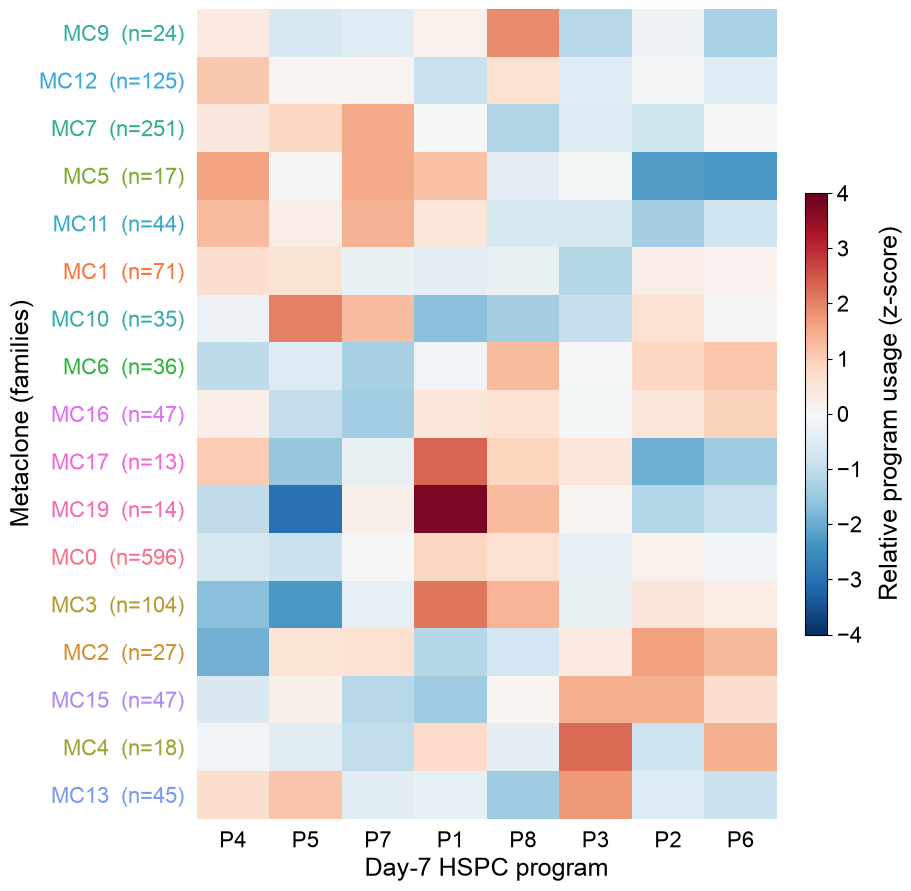

{'output': '/path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911/panels/07a_day7_metaclone_program_usage',
 'unchanged_saved_values': True,
 'zscore_limit': 4.0}

In [11]:
# One raw plot: same saved all-metaclone z-scores; labels use the locked metaclone palette.
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams.update({'font.family':'Arial','font.size':16,'axes.labelsize':18,'xtick.labelsize':16,'ytick.labelsize':16,'svg.fonttype':'none','axes.spines.top':False,'axes.spines.right':False})
mc_colors = {0:'#f77189',1:'#f8763b',2:'#d28e32',3:'#b79932',4:'#9ea231',5:'#7caa31',6:'#31b345',7:'#34b081',9:'#35ae9a',10:'#36acad',11:'#38aac1',12:'#3aa6dd',13:'#7699f4',15:'#b087f4',16:'#df6df4',17:'#f563d8',19:'#f66ab2'}
profiles_z = pd.read_csv(SOURCE / 'tables/metaclone_relative_usage_zscore.csv', index_col=0)
depth = pd.read_csv(SOURCE / 'tables/metaclone_depth.csv', index_col=0)
mc_order = [9,12,7,5,11,1,10,6,16,17,19,0,3,2,15,4,13]
program_order = ['P4','P5','P7','P1','P8','P3','P2','P6']
plot_data = profiles_z.loc[mc_order, program_order]
plot_data.to_csv(BASE / 'tables/07a_plot_values.csv')
fig, ax = plt.subplots(figsize=(9.4,9.2))
limit = max(2., float(np.ceil(np.abs(plot_data.to_numpy()).max()*2)/2))
im = ax.pcolormesh(plot_data.to_numpy(), cmap='RdBu_r', vmin=-limit, vmax=limit, shading='flat', rasterized=False)
ax.invert_yaxis()
ax.set_xticks(np.arange(8)+.5, program_order)
ax.set_yticks(np.arange(len(mc_order))+.5, [f'MC{m}  (n={depth.loc[m,"n_families"]})' for m in mc_order])
for tick, mc in zip(ax.get_yticklabels(), mc_order):
    tick.set_color(mc_colors[mc])
ax.set_xlabel('Day-7 HSPC program'); ax.set_ylabel('Metaclone (families)')
ax.tick_params(length=0,pad=9)
ax.spines[['top','right','bottom','left']].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=.035, pad=.045)
cbar.solids.set_rasterized(False)
cbar.set_label('Relative program usage (z-score)', labelpad=12)
fig.tight_layout()
stem = BASE / 'panels/07a_day7_metaclone_program_usage'
fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
plt.show()
display({'output':str(stem), 'unchanged_saved_values':True, 'zscore_limit':limit})


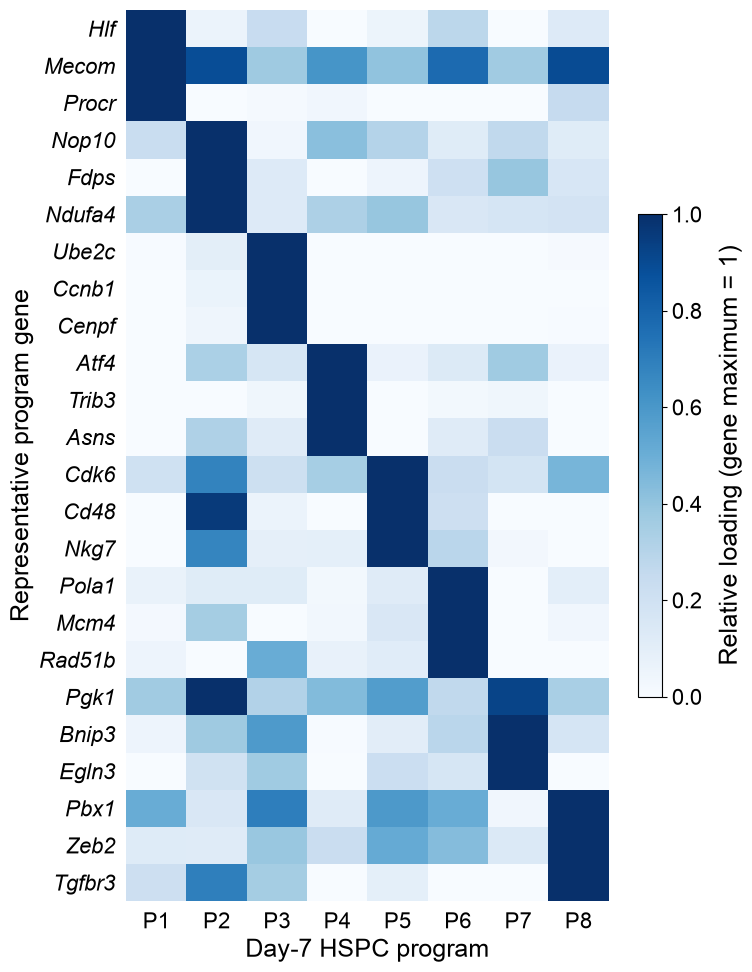

{'output': '/path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911/panels/07b_day7_representative_gene_loadings',
 'representative_gene_selection': 'Manual biological curation within top-40 loading or specificity ranks; not highest-three selection',
 'saved_spectra_unchanged': True}

In [12]:
# One raw plot: three literature-interpretable genes per program, from top-40 loading or specificity ranks.
program_order = list(spectra.index)
selected_genes = curated_genes.sort_values(['program','display_order']).gene.tolist()
assert len(set(selected_genes)) == len(selected_genes)
normalized_loadings = spectra.div(spectra.sum(axis=1), axis=0)
load_matrix = normalized_loadings.loc[program_order, selected_genes].T
relative_loading = load_matrix.div(load_matrix.max(axis=1), axis=0)
relative_loading.to_csv(BASE / 'tables/07b_plot_values.csv')
fig, ax = plt.subplots(figsize=(7.8,10.0))
im = ax.pcolormesh(relative_loading.to_numpy(), cmap='Blues', vmin=0, vmax=1, shading='flat', rasterized=False)
ax.invert_yaxis()
ax.set_xticks(np.arange(8)+.5, program_order)
ax.set_yticks(np.arange(len(selected_genes))+.5, selected_genes, fontstyle='italic')
ax.set_xlabel('Day-7 HSPC program'); ax.set_ylabel('Representative program gene')
ax.tick_params(length=0,pad=8)
ax.spines[['top','right','bottom','left']].set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=.045, pad=.055)
cbar.solids.set_rasterized(False)
cbar.set_label('Relative loading (gene maximum = 1)', labelpad=12)
fig.tight_layout()
stem = BASE / 'panels/07b_day7_representative_gene_loadings'
fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
plt.show()
display({'output':str(stem), 'representative_gene_selection':'Manual biological curation within top-40 loading or specificity ranks; not highest-three selection', 'saved_spectra_unchanged':True})


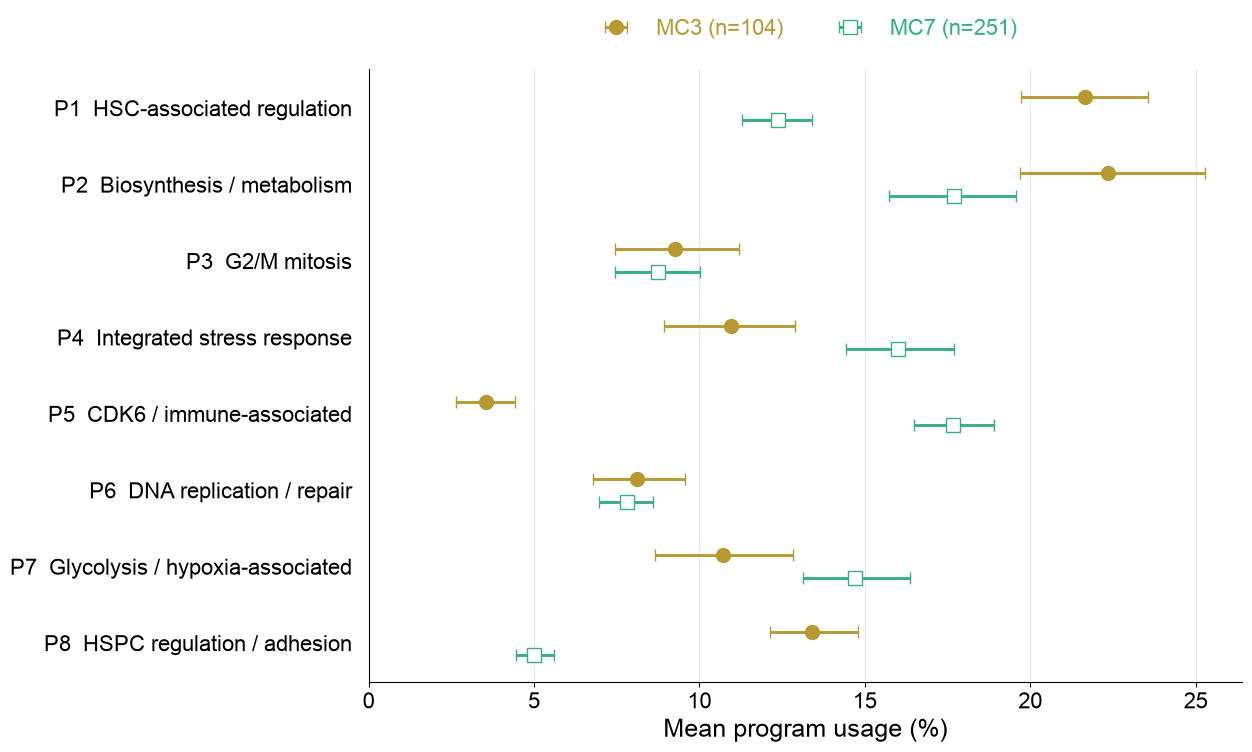

{'output': '/path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911/panels/07c_day7_mc3_mc7_annotated_profiles',
 'all_original_means_and_intervals_retained': True,
 'intervals': 'Existing pointwise 2.5th/97.5th percentiles of 2000 within-metaclone family resamples with NMF and partition fixed; not biological-replicate or contrast confidence intervals'}

In [13]:
# One raw plot: retain every existing MC3/MC7 mean and interval exactly; annotate all eight programs.
plot_table = pd.read_csv(SOURCE / 'tables/06c_profile_plot_values.csv')
program_order = list(spectra.index)
assert plot_table.shape[0] == 16
assert set(plot_table.mc) == {3,7}
plot_table.to_csv(BASE / 'tables/07c_plot_values.csv', index=False)
pd.testing.assert_frame_equal(plot_table, pd.read_csv(BASE / 'tables/07c_plot_values.csv'), check_exact=True)
fig, ax = plt.subplots(figsize=(12.8,7.8))
styles = {3:(mc_colors[3],'o',-.15), 7:(mc_colors[7],'s',.15)}
for mc, (color, marker, offset) in styles.items():
    d = plot_table.loc[plot_table.mc == mc].set_index('program').loc[program_order]
    y = np.arange(8) + offset
    ax.errorbar(100*d['mean'], y, xerr=100*np.vstack([d['mean']-d.lower, d.upper-d['mean']]), fmt=marker, color=color, mec=color, mfc=color if mc == 3 else 'white', markersize=10, elinewidth=2.1, capsize=4.5, label=f'MC{mc} (n={int(d.n_families.iloc[0])})')
ax.set_yticks(np.arange(8), [f'{p}  {annotations.loc[p,"plot_label"]}' for p in program_order])
ax.invert_yaxis(); ax.set_xlim(left=0)
ax.set_xlabel('Mean program usage (%)'); ax.set_ylabel('')
ax.tick_params(axis='y', length=0, pad=12)
ax.grid(axis='x',color='#e6e6e6',linewidth=.7); ax.set_axisbelow(True)
legend = ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(.5,1.015), ncol=2, fontsize=16)
for text, mc in zip(legend.get_texts(), [3,7]):
    text.set_color(mc_colors[mc])
fig.tight_layout()
stem = BASE / 'panels/07c_day7_mc3_mc7_annotated_profiles'
fig.savefig(stem.with_suffix('.svg'), bbox_inches='tight')
fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
plt.show()
display({'output':str(stem), 'all_original_means_and_intervals_retained':True, 'intervals':'Existing pointwise 2.5th/97.5th percentiles of 2000 within-metaclone family resamples with NMF and partition fixed; not biological-replicate or contrast confidence intervals'})


In [14]:
# Manuscript integration packet computed from the unchanged saved estimates.
import re
reference_lookup = {}
for r in references:
    matched = re.match(r'(.*?) \((\d{4})\)\. (.*)', r['citation'])
    authors, year, remaining = matched.groups()
    title = remaining.split('. ')[0]
    reference_lookup[r['key']] = {'authors':authors, 'year':int(year), 'title':title, 'doi':r['doi'], 'url':r['url'], 'citation':r['citation'], 'gene_level_support':r['support']}
numeric_profiles = pd.read_csv(SOURCE / 'tables/06c_profile_plot_values.csv')
means = numeric_profiles.pivot(index='program', columns='mc', values='mean') * 100
paragraphs = [
    'Gene-level inspection placed the eight programs in a hematopoietic context (Figure 7B). P1 contained Hlf, Mecom and Procr, supporting an HSC-associated regulatory annotation [Komorowska2017; Yokomizo2019]. P8 combined Pbx1, Zeb2 and Runx1 with receptor, adhesion and cytoskeletal genes, including Tgfbr3, Ncam2 and Itga6 [Ficara2008; Goossens2011]. P4 contained the ATF4-associated stress-response genes Trib3, Asns and Ddit3; P7 combined glycolytic enzymes with Bnip3 and Egln3. P5 contained Cdk6 and Cd48 together with immune-associated genes, including Nkg7, Tespa1 and Fcer1g, rather than a coherent platelet-specific identity. P2 encompassed broad biosynthetic/metabolic machinery, whereas P3 and P6 separated mitotic from DNA-replication/repair-associated expression.',
    f'These molecular mixtures distinguished the early relatives of the MC3 and MC7 reference histories (Figure 7C). The largest observed difference was in the mixed CDK6/immune-associated program P5, with mean fractional usage of {means.loc["P5",3]:.1f}% in MC3 and {means.loc["P5",7]:.1f}% in MC7. The Cdk6/Cd48 content is compatible with a progenitor-activation context [Laurenti2015; Boles2011], without establishing mature immune identity. MC3 instead showed higher usage of P1 ({means.loc["P1",3]:.1f}% versus {means.loc["P1",7]:.1f}%) and P8 ({means.loc["P8",3]:.1f}% versus {means.loc["P8",7]:.1f}%). MC7 had higher stress-associated P4 ({means.loc["P4",7]:.1f}% versus {means.loc["P4",3]:.1f}%) and glycolysis/hypoxia-associated P7 ({means.loc["P7",7]:.1f}% versus {means.loc["P7",3]:.1f}%) usage, while the mitotic and replication-associated profiles were more similar.',
    'Thus, metaclones connect distinct reference histories to overlapping early regulatory, activation-associated and metabolic programs. These retrospective descriptions do not establish functional stem-cell identity, a causal differentiation mechanism or prediction of mutation response. In particular, stress responses and glycolysis can support HSC maintenance, so neither is a unidirectional marker of differentiation [vanGalen2018; Takubo2013].',
]
selection = 'Three representative genes per program were selected for biological interpretability from the top 40 raw-loading or specificity ranks, independently of MC3–MC7 effect magnitude. They are not necessarily the three highest-ranking genes or exclusive to one program. All 16,000 gene weights, all ranks, and the complete pre-existing enrichment family remain available.'
panel_paths = {'A':'panels/07a_day7_metaclone_program_usage.png','B':'panels/07b_day7_representative_gene_loadings.png','C':'panels/07c_day7_mc3_mc7_annotated_profiles.png'}
packet = {'programs':[{'program':p,'short_label':r.label,'anchor_genes':r.anchors,'additional_genes':r.additional_genes,'interpretation':r.interpretation,'caveat':r.boundary,'primary_references':[reference_lookup[k] for k in r.references]} for p,r in annotations.iterrows()], 'mc3_mc7_profiles':numeric_profiles.to_dict(orient='records'), 'proposed_results_paragraphs':paragraphs, 'figure7b_selection_description':selection, 'panels':panel_paths, 'interval_definition':'Existing pointwise 2.5th/97.5th percentiles of 2000 within-metaclone family resamples; fixed NMF and fixed partition. No new bootstrap, contrast test, or biological-replicate interval.', 'source_model':'analysis_workspace/singh/singh_reference_response_20260911/programs/0002_rna_normalized_day7_programs.ipynb', 'environment':environment, 'references':reference_lookup}
(BASE / 'reports/manuscript_annotation.json').write_text(json.dumps(packet, indent=2))
report = ['# Singh program annotations for manuscript integration', '', 'Gene-based descriptive annotation only. Existing chronoclone environment: `/path/to/ChronoClone/.runtime/chronoclone`; kernel `chronoclone`.', '', '## Recommended biological reading', '']
report.extend(paragraphs)
report.extend(['', '## All-eight annotation registry', '', '| Program | Descriptive label | Representative genes | Interpretation boundary |', '|---|---|---|---|'])
for p,r in annotations.iterrows():
    report.append(f'| {p} | {r.label} | {", ".join(r.anchors)} | {r.boundary} |')
report.extend(['', '## Figure captions and selection', '', '**7A.** Family-balanced relative program usage across all 17 reference metaclones. Values are the unchanged saved z-scores, centered/scaled using the previously declared metaclones with at least 32 Day-7 cells. Parenthetical n denotes resolved Day-7 families. No metaclone-specific significance tests.', '', '**7B.** Relative spectrum loadings for representative program-associated genes. Each program spectrum is normalized to sum to one and each displayed gene is scaled to its maximum across programs. ' + selection, '', '**7C.** Mean fractional program usage in MC3 and MC7 Day-7 HSPCs, with descriptive gene-grounded program labels. Means and intervals are copied unchanged from the retained analysis. ' + packet['interval_definition'] + ' Both source populations remain pooled HSPCs; these labels do not subdivide or reassign cells.', '', '## Important boundaries', '', '- Program labels are supported by gene content and literature, not new statistically significant MC identities. The original selected ontology terms and q-values remain in a transparency table; those q-values do not quantify confidence in the new manual names.', '- P5 is the largest observed MC3–MC7 program-usage difference and is explicitly included. Its mixed immune genes span several mature contexts, excluding a justified platelet-only, NK-only or mast-only call.', '- P8 is not a neuronal program. MED12L should not inherit functional claims from its distinct paralog MED12.', '- P7 includes Gt(ROSA)26Sor among its retained high-specificity features; this locus is not used as a biological annotation anchor. The saved fit and original RNA eligibility remain unchanged in this annotation-only task.', '- No causal interpretation, prospective prediction, sex/replicate modeling, HSC/MPP split, new DE, enrichment rerun, NMF refit, or new significance threshold.', '', '## Primary references', ''])
for k,r in reference_lookup.items():
    report.append(f'**{k}** {r["citation"]} DOI: [{r["doi"]}](https://doi.org/{r["doi"]}). {r["gene_level_support"]}')
(BASE / 'PROGRAM_ANNOTATION_HANDOFF.md').write_text('\n\n'.join(report))
display(Markdown('\n\n'.join(paragraphs)))
display({'integration_packet':str(BASE / 'reports/manuscript_annotation.json'), 'raw_panels':panel_paths, 'proposed_prose_word_count':sum(len(p.split()) for p in paragraphs)})


Gene-level inspection placed the eight programs in a hematopoietic context (Figure 7B). P1 contained Hlf, Mecom and Procr, supporting an HSC-associated regulatory annotation [Komorowska2017; Yokomizo2019]. P8 combined Pbx1, Zeb2 and Runx1 with receptor, adhesion and cytoskeletal genes, including Tgfbr3, Ncam2 and Itga6 [Ficara2008; Goossens2011]. P4 contained the ATF4-associated stress-response genes Trib3, Asns and Ddit3; P7 combined glycolytic enzymes with Bnip3 and Egln3. P5 contained Cdk6 and Cd48 together with immune-associated genes, including Nkg7, Tespa1 and Fcer1g, rather than a coherent platelet-specific identity. P2 encompassed broad biosynthetic/metabolic machinery, whereas P3 and P6 separated mitotic from DNA-replication/repair-associated expression.

These molecular mixtures distinguished the early relatives of the MC3 and MC7 reference histories (Figure 7C). The largest observed difference was in the mixed CDK6/immune-associated program P5, with mean fractional usage of 3.6% in MC3 and 17.7% in MC7. The Cdk6/Cd48 content is compatible with a progenitor-activation context [Laurenti2015; Boles2011], without establishing mature immune identity. MC3 instead showed higher usage of P1 (21.6% versus 12.4%) and P8 (13.4% versus 5.0%). MC7 had higher stress-associated P4 (16.0% versus 10.9%) and glycolysis/hypoxia-associated P7 (14.7% versus 10.7%) usage, while the mitotic and replication-associated profiles were more similar.

Thus, metaclones connect distinct reference histories to overlapping early regulatory, activation-associated and metabolic programs. These retrospective descriptions do not establish functional stem-cell identity, a causal differentiation mechanism or prediction of mutation response. In particular, stress responses and glycolysis can support HSC maintenance, so neither is a unidirectional marker of differentiation [vanGalen2018; Takubo2013].

{'integration_packet': '/path/to/ChronoClone/analysis_workspace/singh/singh_program_annotation_20260911/reports/manuscript_annotation.json',
 'raw_panels': {'A': 'panels/07a_day7_metaclone_program_usage.png',
  'B': 'panels/07b_day7_representative_gene_loadings.png',
  'C': 'panels/07c_day7_mc3_mc7_annotated_profiles.png'},
 'proposed_prose_word_count': 242}

In [15]:
# Source preservation and output integrity; no new statistical tests.
import xml.etree.ElementTree as ET
for row in source_manifest.itertuples():
    assert hashlib.sha256(Path(row.source).read_bytes()).hexdigest() == row.sha256
checks=[]
for svg in sorted((BASE / 'panels').glob('*.svg')):
    elements=list(ET.parse(svg).getroot().iter())
    texts=[e for e in elements if e.tag.endswith('}text')]
    images=[e for e in elements if e.tag.endswith('}image')]
    checks.append({'panel':svg.stem,'editable_text_elements':len(texts),'raster_images':len(images),'png_exists':svg.with_suffix('.png').exists()})
    assert len(texts)>0 and len(images)==0 and svg.with_suffix('.png').exists()
pd.DataFrame(checks).to_csv(BASE / 'reports/svg_checks.csv', index=False)
outputs=[p for sub in ['tables','panels'] for p in (BASE/sub).glob('*') if p.is_file()]
pd.DataFrame([{'path':str(p.relative_to(BASE)),'sha256':hashlib.sha256(p.read_bytes()).hexdigest(),'bytes':p.stat().st_size} for p in sorted(outputs)]).to_csv(BASE / 'reports/output_manifest.csv', index=False)
display(pd.DataFrame(checks))
display({'source_hashes_unchanged':len(source_manifest), 'all_programs_descriptively_annotated':len(annotations), 'retained_NMF_model':'ordinary fixed-K8 NMF', 'new_model_fits':0, 'new_hypothesis_tests':0, 'program_and_metaclone_counts_unchanged':True})


,panel,editable_text_elements,raster_images,png_exists
0,07a_day7_metaclone_program_usage,37,0,True
1,07b_day7_representative_gene_loadings,41,0,True
2,07c_day7_mc3_mc7_annotated_profiles,17,0,True


{'source_hashes_unchanged': 11,
 'all_programs_descriptively_annotated': 8,
 'retained_NMF_model': 'ordinary fixed-K8 NMF',
 'new_model_fits': 0,
 'new_hypothesis_tests': 0,
 'program_and_metaclone_counts_unchanged': True}